#### Figures for the paper

Small figures for the IEEE paper (one column wide, about 3.5 inch). They only use the saved results
and the processed data, so nothing is trained here.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import acf

In [2]:
plt.rcParams.update({"font.family": "serif", "font.size": 8, "axes.titlesize": 8, "legend.fontsize": 7,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#dddddd", "grid.linewidth": 0.5, "lines.linewidth": 1.2})

NAMES = {"pjme": "PJM East (regional)", "uci": "UCI household"}
MODELS = ["rf", "xgb", "lstm", "gru", "cnn_lstm", "attention"]
LABELS = {"naive": "Seasonal naive", "rf": "Random Forest", "xgb": "XGBoost", "lstm": "LSTM", "gru": "GRU",
          "cnn_lstm": "CNN-LSTM", "attention": "Attention (TFT)"}
COLORS = {"rf": "#2a78d6", "xgb": "#eb6834", "lstm": "#eda100", "gru": "#1baf7a", "cnn_lstm": "#e87ba4",
          "attention": "#6250d6"}
MARKERS = {"rf": "o", "xgb": "s", "lstm": "^", "gru": "D", "cnn_lstm": "v", "attention": "P"}
W = 3.5

#### Fig. 2 - daily profile and autocorrelation

Demand divided by its mean, so both datasets fit on the same scale. Training data only.

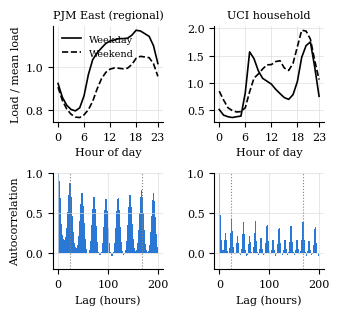

In [3]:
fig, ax = plt.subplots(2, 2, figsize=(W, 3.2))
for i, name in enumerate(["pjme", "uci"]):
    train = pd.read_parquet(f"../data/processed/{name}_train.parquet")
    y = train["load"] / train["load"].mean()
    for wk, lab, ls in [(0, "Weekday", "-"), (1, "Weekend", "--")]:
        prof = y[train["weekend"] == wk].groupby(train["hour"]).mean()
        ax[0, i].plot(prof.index, prof.values, ls, color="black", label=lab)
    ax[0, i].set_title(NAMES[name])
    ax[0, i].set_xticks([0, 6, 12, 18, 23])
    ax[0, i].set_xlabel("Hour of day")

    r = acf(train["load"], nlags=200)
    ax[1, i].bar(range(len(r)), r, width=1.0, color="#2a78d6")
    for lag in [24, 168]:
        ax[1, i].axvline(lag, color="grey", ls=":", lw=0.8)
    ax[1, i].set_ylim(-0.2, 1)
    ax[1, i].set_xlabel("Lag (hours)")

ax[0, 0].set_ylabel("Load / mean load")
ax[1, 0].set_ylabel("Autocorrelation")
ax[0, 0].legend(frameon=False, loc="upper left")
fig.tight_layout()
fig.savefig("../figures/08_paper_patterns.png", dpi=300)
plt.show()

#### Fig. 3 - error against horizon

RMSE divided by the mean test load (nRMSE), mean over the three seeds. The seasonal naive model is the same
for all horizons, so it is drawn as a grey line.

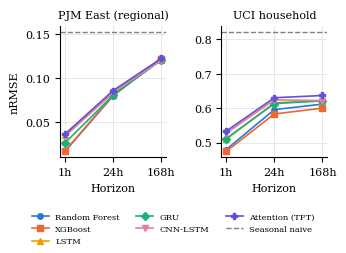

In [4]:
scores = pd.concat([pd.read_csv("../results/baseline_scores.csv"), pd.read_csv("../results/deep_scores.csv")])
mean = scores.groupby(["dataset", "model", "horizon"])["rmse"].mean()

fig, ax = plt.subplots(1, 2, figsize=(W, 2.5))
for i, name in enumerate(["pjme", "uci"]):
    level = pd.read_parquet(f"../data/processed/{name}_test.parquet")["load"].mean()
    for m in MODELS:
        v = [mean[(name, m, h)] / level for h in [1, 24, 168]]
        ax[i].plot([0, 1, 2], v, marker=MARKERS[m], ms=4, color=COLORS[m], label=LABELS[m])
    ax[i].axhline(mean[(name, "naive", 1)] / level, color="grey", ls="--", lw=1, label=LABELS["naive"])
    ax[i].set_xticks([0, 1, 2], ["1h", "24h", "168h"])
    ax[i].set_xlabel("Horizon")
    ax[i].set_title(NAMES[name])
ax[0].set_ylabel("nRMSE")
h, l = ax[0].get_legend_handles_labels()
fig.legend(h, l, loc="lower center", ncol=3, frameon=False, fontsize=6)
fig.tight_layout(rect=(0, 0.17, 1, 1))
fig.savefig("../figures/08_paper_rmse_horizon.png", dpi=300)
plt.show()

#### Fig. 4 - error by hour of day (24h ahead)

RMSE of each hour of the day for XGBoost and GRU, next to the standard deviation of the training load in
that hour. All three are divided by their own mean over the 24 hours, so they share one axis.

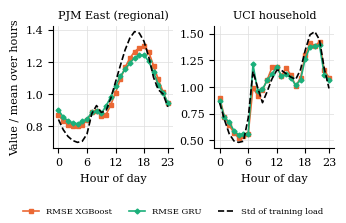

In [5]:
err = pd.read_csv("../results/error_by_period.csv")
fig, ax = plt.subplots(1, 2, figsize=(W, 2.2))
for i, name in enumerate(["pjme", "uci"]):
    e = err[(err.dataset == name) & (err.horizon == 24) & (err.by == "hour")].copy()
    e["group"] = e["group"].astype(int)
    for m in ["xgb", "gru"]:
        s = e[e.model == m].set_index("group")["rmse"].sort_index()
        ax[i].plot(s.index, s / s.mean(), color=COLORS[m], marker=MARKERS[m], ms=2.5, label=f"RMSE {LABELS[m]}")
    train = pd.read_parquet(f"../data/processed/{name}_train.parquet")
    sd = train["load"].groupby(train["hour"]).std()
    ax[i].plot(sd.index, sd / sd.mean(), color="black", ls="--", label="Std of training load")
    ax[i].set_xticks([0, 6, 12, 18, 23])
    ax[i].set_xlabel("Hour of day")
    ax[i].set_title(NAMES[name])
ax[0].set_ylabel("Value / mean over hours")
h, l = ax[0].get_legend_handles_labels()
fig.legend(h, l, loc="lower center", ncol=3, frameon=False, fontsize=6)
fig.tight_layout(rect=(0, 0.1, 1, 1))
fig.savefig("../figures/08_paper_error_by_hour.png", dpi=300)
plt.show()

#### Fig. 5 - one test week, 24h ahead

PJM: the week with the highest load in the test period (summer peak). UCI: the first full week (Monday to Sunday)
of the test period. Mean of the three seeds.

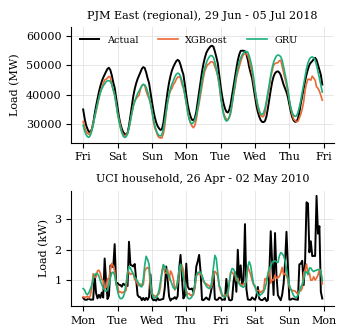

In [6]:
fig, ax = plt.subplots(2, 1, figsize=(W, 3.4))
for i, name in enumerate(["pjme", "uci"]):
    p = {m: pd.read_parquet(f"../results/predictions/{name}_{m}_h24.parquet") for m in ["xgb", "gru"]}
    actual = p["xgb"]["actual"]
    if name == "pjme":
        start = actual.idxmax().normalize() - pd.Timedelta(days=3)
    else:
        first = actual.index.min().normalize() + pd.Timedelta(days=1)
        start = first + pd.Timedelta(days=(7 - first.dayofweek) % 7)
    end = start + pd.Timedelta(days=7) - pd.Timedelta(hours=1)
    ax[i].plot(actual.loc[start:end], color="black", lw=1.4, label="Actual")
    for m in ["xgb", "gru"]:
        pred = p[m][["seed_0", "seed_1", "seed_2"]].mean(axis=1)
        ax[i].plot(pred.loc[start:end], color=COLORS[m], label=LABELS[m])
    ax[i].set_title(f"{NAMES[name]}, {start:%d %b} - {end:%d %b %Y}")
    ax[i].set_ylabel("Load (MW)" if name == "pjme" else "Load (kW)")
    ax[i].xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%a"))
ax[0].set_ylim(top=63000)
ax[0].legend(frameon=False, ncol=3, loc="upper left")
fig.tight_layout()
fig.savefig("../figures/08_paper_forecast_week.png", dpi=300)
plt.show()